John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

In [1]:
# load packages
library(tidyverse)
library(tidymodels)

# set random seed
set.seed(42)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.10     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.3.3      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ scales::discard() mask

In [2]:
test_accuracies <- list()
song_accuracies <- list()

folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    print(file)
    name <- as.character(file)
    if (str_detect(file, "test_accuracies")) {
        test_accuracies <- append(test_accuracies, list("{name}" = read_csv(file)))
    } else if (str_detect(file, "song_accuracies")) {
        song_accuracies <- append(song_accuracies, list("{file}" = read_csv(file)))
    }
}

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs since last own song_song_accuracies.csv"


Rows: 206 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/All songs since last own song_test_accuracies.csv"


Rows: 11 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): ID
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Attention_song_accuracies.csv"


Rows: 72 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


... (2 outputs left out)

[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Own Song History_song_accuracies.csv"


Rows: 201 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (2): ID, model
dbl (3): UST, estimated_accuracy, n

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\results/Own Song History_test_accuracies.csv"


Rows: 11 Columns: 2
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): ID
dbl (1): estimated_accuracy

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


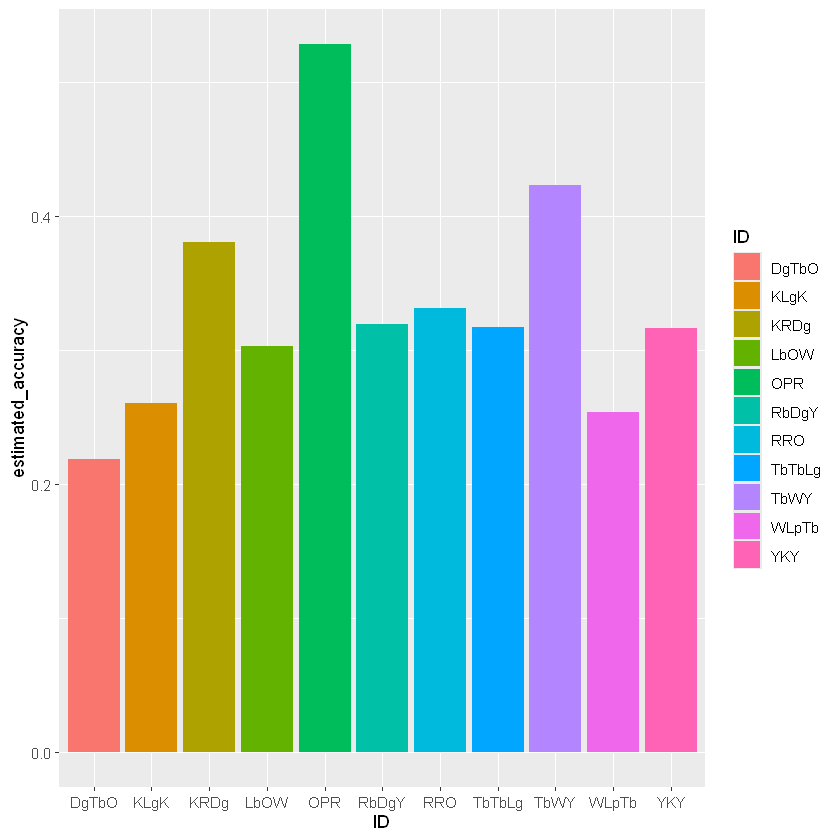

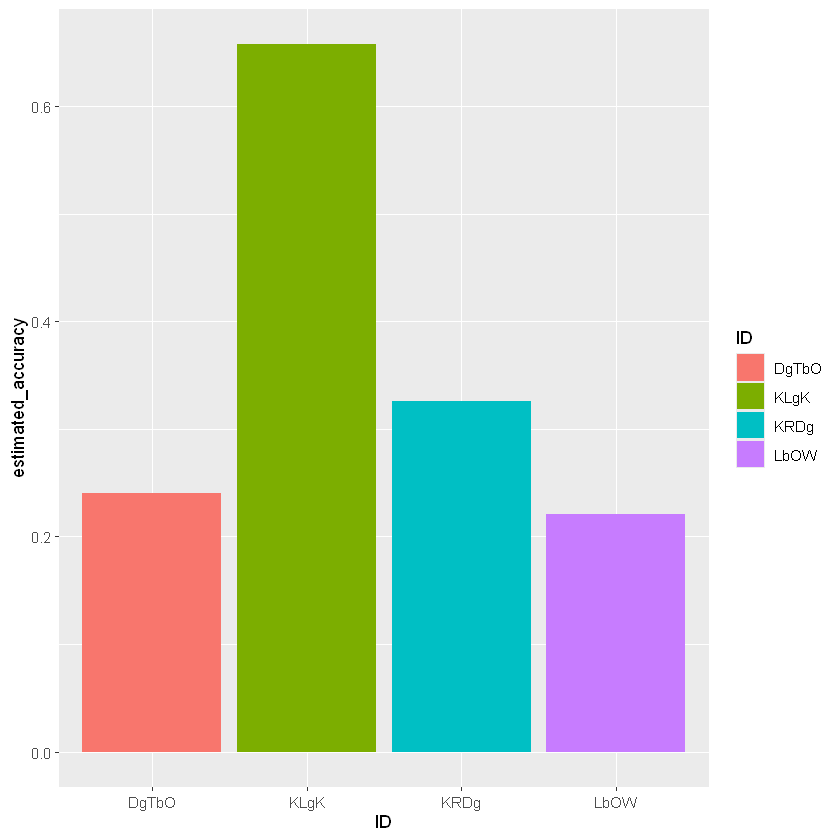

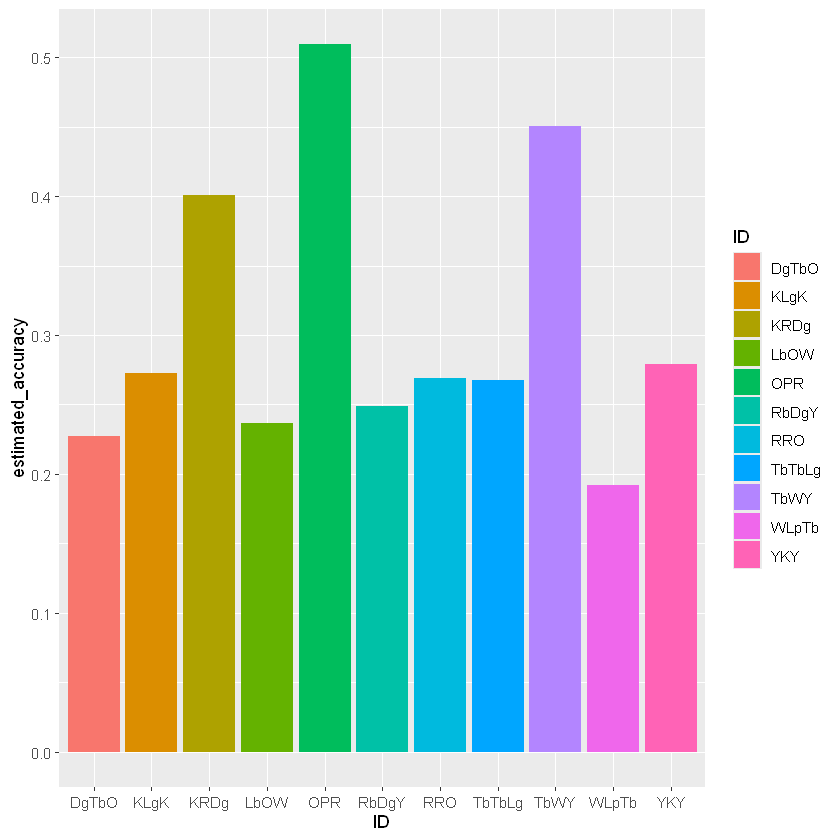

In [3]:
for (data in test_accuracies) {
    plot <- ggplot(data = data, aes(x=ID, y=estimated_accuracy, fill=ID)) +
        geom_col()
    print(plot)
}

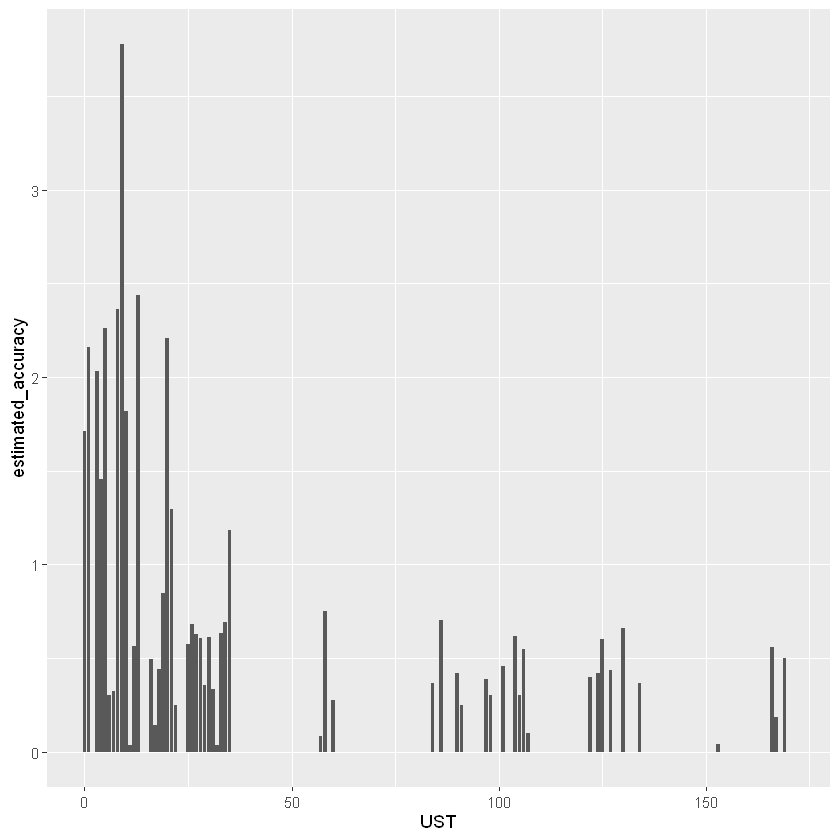

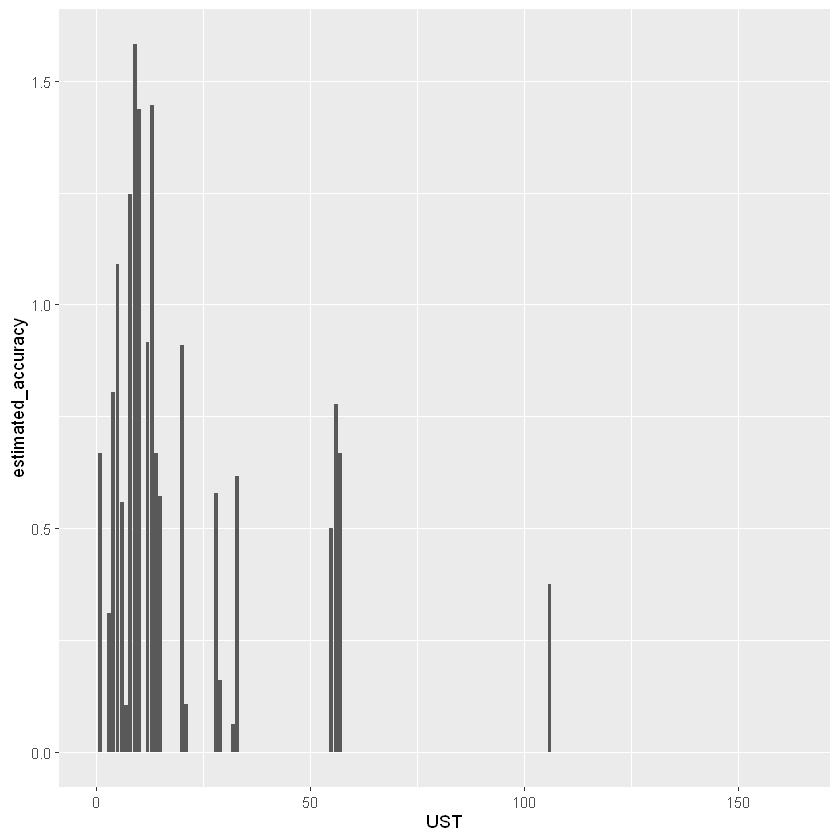

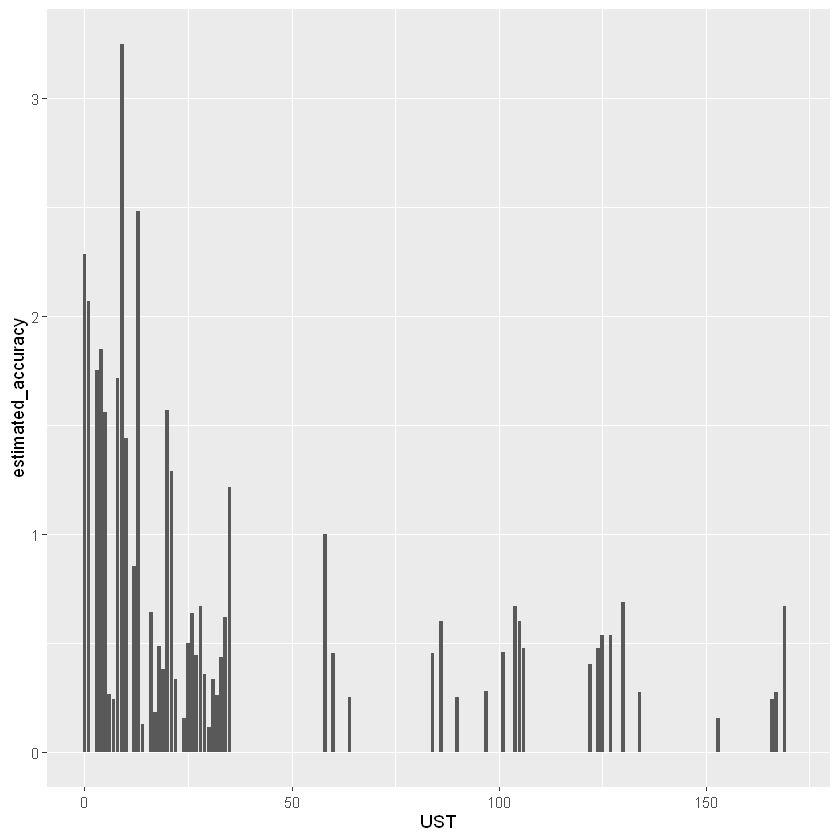

In [4]:
for (data in song_accuracies) {
    plot <- ggplot(data = data, aes(x=UST, y=estimated_accuracy)) +
        geom_col()
    print(plot)
}

In [5]:
for (table in song_accuracies) {
    View(table)
}

ID,UST,estimated_accuracy,model,n
<chr>,<dbl>,<dbl>,<chr>,<dbl>
DgTbO,33,0.63063063,All songs since last own song,NA
DgTbO,25,0.57142857,All songs since last own song,NA
DgTbO,20,0.42857143,All songs since last own song,12
DgTbO,4,0.16000000,All songs since last own song,NA
DgTbO,10,0.13186813,All songs since last own song,34
DgTbO,8,0.11864407,All songs since last own song,55
DgTbO,7,0.10169492,All songs since last own song,NA
DgTbO,153,0.03921569,All songs since last own song,NA
DgTbO,32,0.03703704,All songs since last own song,NA


ID,UST,estimated_accuracy,model,n
<chr>,<dbl>,<dbl>,<chr>,<dbl>
DgTbO,33,0.61538462,Attention,NA
DgTbO,20,0.50793651,Attention,NA
DgTbO,10,0.31147541,Attention,56
DgTbO,8,0.15094340,Attention,67
DgTbO,7,0.10344828,Attention,NA
DgTbO,4,0.07692308,Attention,NA
DgTbO,32,0.06250000,Attention,NA
DgTbO,1,0.00000000,Attention,NA
DgTbO,5,0.00000000,Attention,32


ID,UST,estimated_accuracy,model,n
<chr>,<dbl>,<dbl>,<chr>,<dbl>
DgTbO,25,0.50000000,Own Song History,NA
DgTbO,33,0.43589744,Own Song History,NA
DgTbO,20,0.41176471,Own Song History,12
DgTbO,32,0.26086957,Own Song History,NA
DgTbO,7,0.24193548,Own Song History,NA
DgTbO,10,0.20000000,Own Song History,34
DgTbO,12,0.15625000,Own Song History,2
DgTbO,153,0.15384615,Own Song History,NA
DgTbO,1,0.13953488,Own Song History,63


Warning message:
"Removed 95 rows containing missing values or values outside the scale range
(`geom_point()`)."
Warning message:
"Removed 41 rows containing missing values or values outside the scale range
(`geom_point()`)."


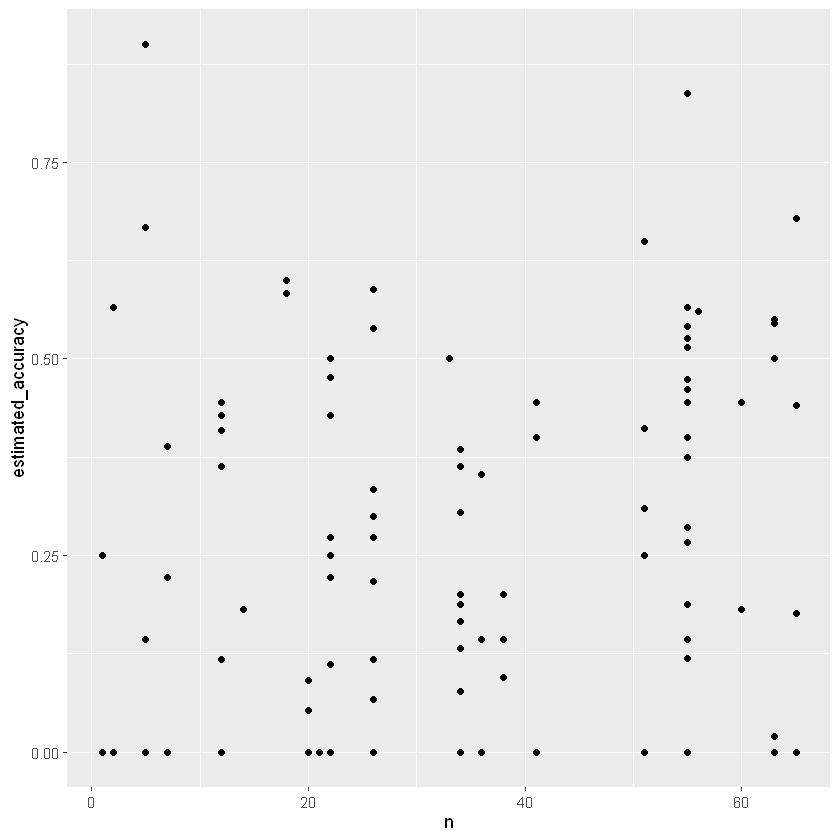

Warning message:
"Removed 89 rows containing missing values or values outside the scale range
(`geom_point()`)."


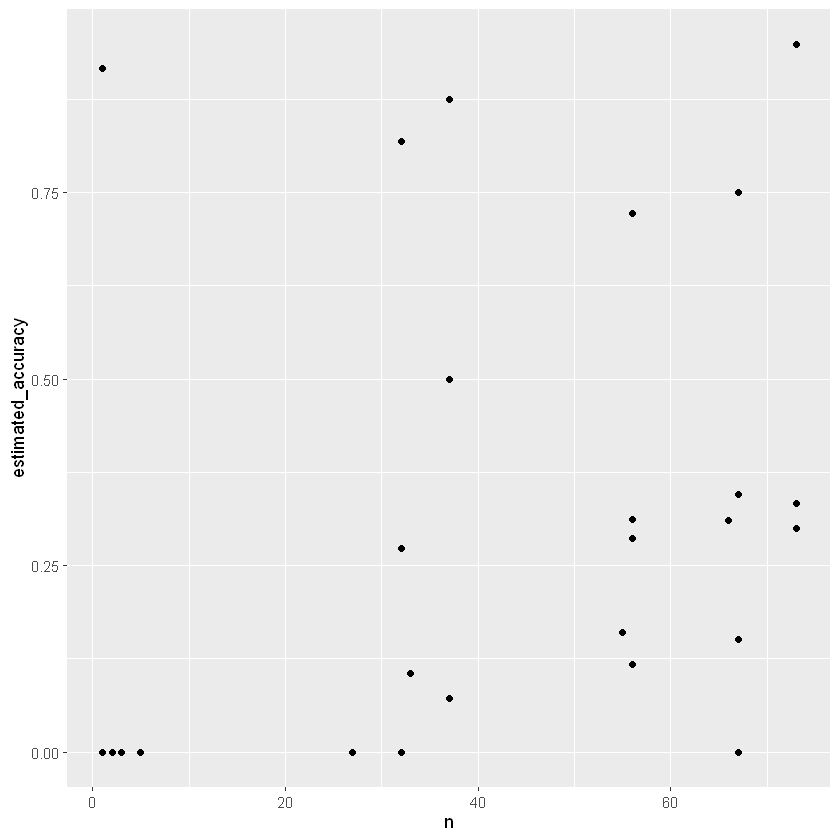

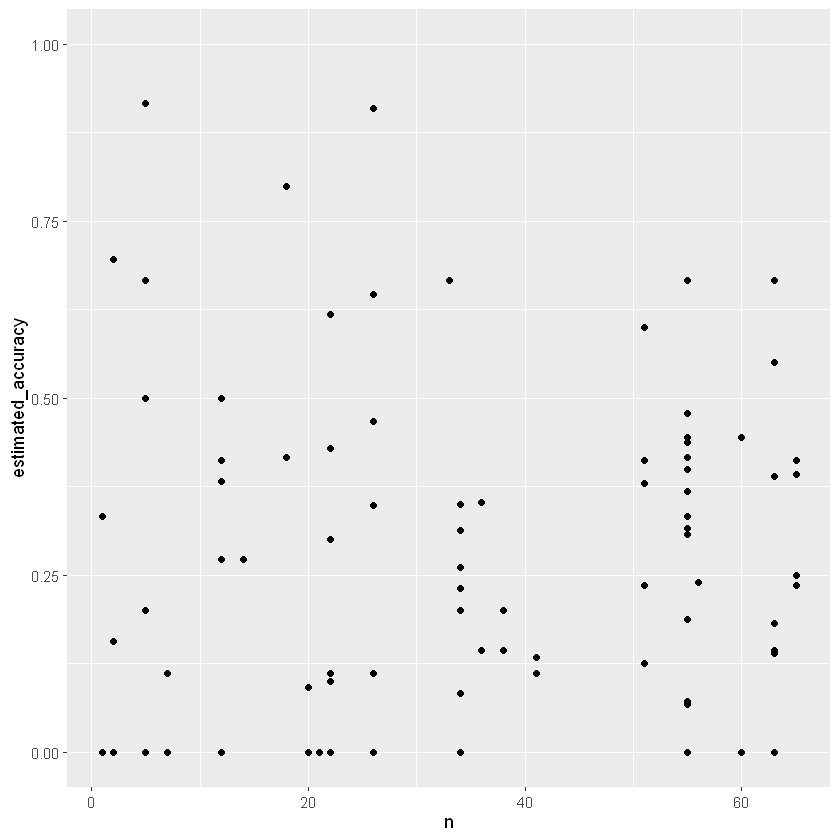

In [6]:
for (table in song_accuracies) {
    plot <- ggplot(data=table) + 
        aes(x=n, y=estimated_accuracy) +
        geom_point()
    print(plot)
}

In [7]:
song_accuracies

ID,UST,estimated_accuracy,model,n
<chr>,<dbl>,<dbl>,<chr>,<dbl>
DgTbO,33,0.63063063,All songs since last own song,NA
DgTbO,25,0.57142857,All songs since last own song,NA
DgTbO,20,0.42857143,All songs since last own song,12
DgTbO,4,0.16000000,All songs since last own song,NA
DgTbO,10,0.13186813,All songs since last own song,34
DgTbO,8,0.11864407,All songs since last own song,55
DgTbO,7,0.10169492,All songs since last own song,NA
DgTbO,153,0.03921569,All songs since last own song,NA
DgTbO,32,0.03703704,All songs since last own song,NA
